You measure the position of a star $N$ times with the *same* telescope i.e. errors are homoscedastic. Let's say the underlying process is Gaussian, the true position is $\mu = 1$ (in suitable units), and the erorrs are $\sigma=0.2$

### Part 1

- Generate fake measurements. Treat each of these observations as an estimate of the true distribution. So we'll center a Gaussian (with the known $\sigma$) at each point. This is the probability of each data point, $p(x_i|\mu,\sigma)$.
- Plot each of the individual likelihoods  separately.  Also plot their product (i.e. the likelihood of the dataset $\{x_i\}$). Make sure the x grid has enough points.
- Just read off the maximum likelihood solution (e.g. using `np.argsort`) 
- Compare it with the MLE estimator derived above

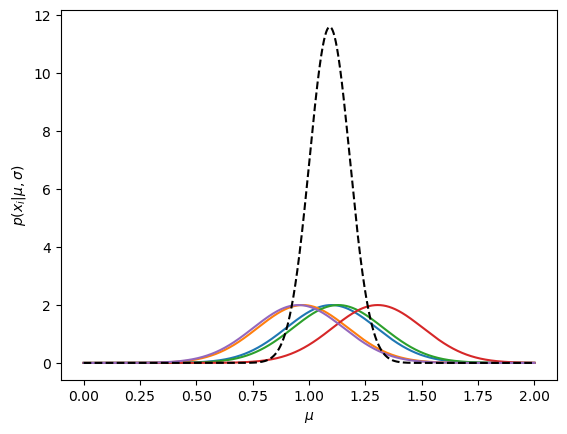

In [15]:
import numpy as np
from scipy.stats import norm
from matplotlib import pyplot as plt

np.random.seed(42)

random_gaussian = norm.rvs(1, 0.2, 5)

mu_grid = np.linspace(0.0,2.0,10000)

likelihood = 1 

for i in random_gaussian: 
    likelihood_i = norm.pdf(mu_grid,loc=i,scale=0.2)

    likelihood *= likelihood_i
    
    plt.plot(mu_grid,likelihood_i)

plt.plot(mu_grid,likelihood,ls='--', c='black', label=r'$L(\{x\})$')
plt.xlabel(r'$\mu$')
plt.ylabel(r'$p(x_i|\mu,\sigma)$')
plt.show()


In [16]:
#read of the maximum likelihood solution and compare it with the MLE which is the mean

sort_likelihood = np.argsort(likelihood)

max_index = sort_likelihood[-1]
max_solution = mu_grid[max_index]

mle_analitical = np.mean(random_gaussian)

error = abs(max_solution - mle_analitical)

print(max_solution,mle_analitical,error)

1.0917091709170919 1.0918005948650173 9.142394792549524e-05


### Part 2

Check the Fisher matrix error estimate makes sense
- do a rough $2^\mathrm{nd}$ order differentation of our log-likelihood function with `np.diff`, 
- divide through by our $\Delta \theta^2$ to get the correct normalization, 
- multiply by $-1$, 
- then take the square root.
- Compare with the Fisher matrix error derived above
- Plot a Gaussian at the measured $\mu$ with this error as the scale to see if it matches the numerical likelihood distribution. (The normalization won't be captured, you can rescale it as you like to check it agrees) 


0.08944271909623851 0.08944271909999159


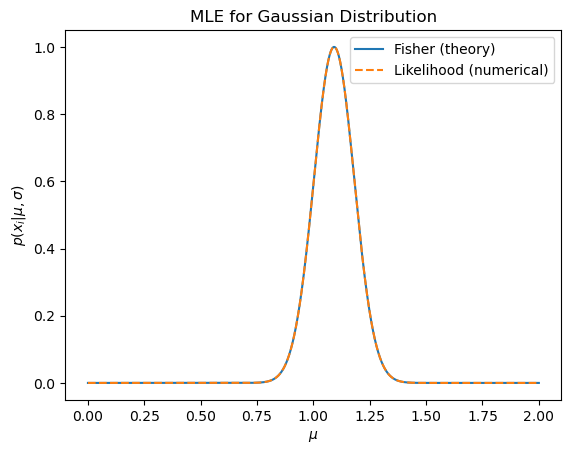

In [17]:
log_likelihood = np.log(likelihood)

second_derivative = np.diff(log_likelihood, n=2)

delta_theta = mu_grid[1] - mu_grid[0]
normalized_second_derivative = second_derivative/(delta_theta**2)

#take the inverse of the square root not the square root 
fisher_estimate = np.sqrt(1/(normalized_second_derivative[max_index -1]* (- 1)))

theoretical_fisher = 0.2/np.sqrt(5)

print(fisher_estimate,theoretical_fisher)

new_curve = norm.pdf(mu_grid,mle_analitical,fisher_estimate)
new_curve_normalized = new_curve/np.max(new_curve)

new_likelihood = likelihood/np.max(likelihood)

plt.plot(mu_grid,new_curve_normalized, label='Fisher (theory)')
plt.plot(mu_grid,new_likelihood, ls='dashed', label='Likelihood (numerical)')

plt.xlabel(r'$\mu$') 
plt.ylabel(r'$p(x_i|\mu,\sigma)$') 
plt.title('MLE for Gaussian Distribution')
plt.legend()

### Part 3

Let's make our model more realistic. Our $N$ measurements were taken in different nights, where the sky behaved differently (i.e. errors are heteoscedastic). Let's assume that each measurment has a $\sigma_i$ that is normally distributed with mean $0.2$ and standard deviation $0.05$

- Generalize your code from above to this case

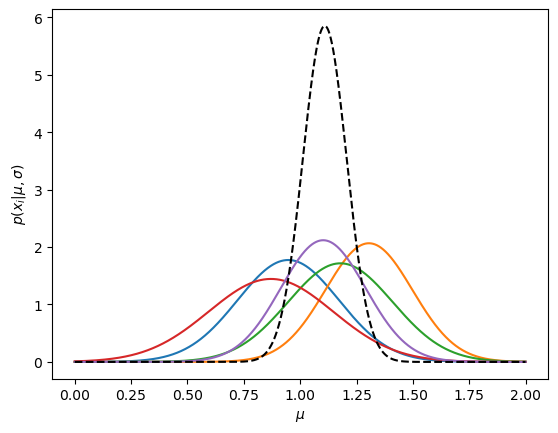

In [18]:
np.random.seed(42)
sigmas = norm.rvs(0.2,0.05,5)

random_gaussian = norm.rvs(1,sigmas)

likelihood = 1 

for x_i, sigma_i in zip(random_gaussian,sigmas):
    
    likelihood_i = norm.pdf(mu_grid,x_i,sigma_i)
    likelihood *= likelihood_i

    plt.plot(mu_grid,likelihood_i)


plt.plot(mu_grid,likelihood,ls='--', c='black', label=r'$L(\{x\})$')

plt.xlabel(r'$\mu$')
plt.ylabel(r'$p(x_i|\mu,\sigma)$')
plt.show()


In [19]:
#read of the maximum likelihood solution and compare it with the MLE which is the median

sort_likelihood = np.argsort(likelihood)

max_index = sort_likelihood[-1]
max_solution = mu_grid[max_index]

mle_analitical = np.sum(random_gaussian/sigmas**2) / np.sum(1/sigmas**2)

error = abs(max_solution - mle_analitical)

print(max_solution,mle_analitical,error)

1.109110911091109 1.1091807602137775 6.984912266849719e-05


0.0969273939646886 0.09692739397962051


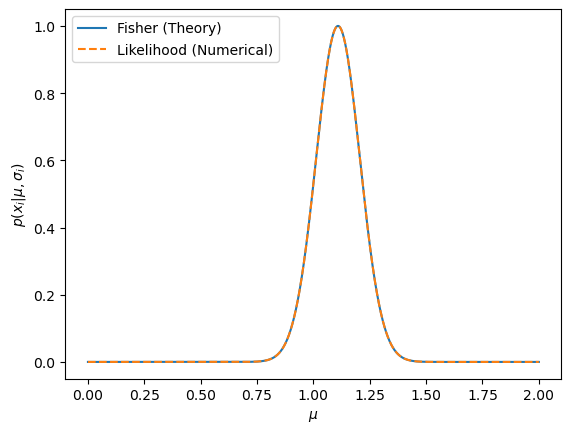

In [20]:
log_likelihood = np.log(likelihood)

second_derivative = np.diff(log_likelihood, n=2)

delta_theta = mu_grid[1] - mu_grid[0]
normalized_second_derivative = second_derivative/(delta_theta**2)

#take the inverse of the square root not the square root 
fisher_estimate = np.sqrt(1/(normalized_second_derivative[max_index -1]* (- 1)))

theoretical_fisher = np.sqrt(1/np.sum(1/sigmas**2))

print(fisher_estimate,theoretical_fisher)

new_curve = norm.pdf(mu_grid,mle_analitical,fisher_estimate)
new_curve_normalized = new_curve/np.max(new_curve)

new_likelihood = likelihood/np.max(likelihood)

plt.plot(mu_grid,new_curve_normalized, label='Fisher (Theory)')
plt.plot(mu_grid,new_likelihood,ls='dashed',label='Likelihood (Numerical)')
plt.xlabel(r'$\mu$') 
plt.ylabel(r'$p(x_i|\mu,\sigma_i)$')
plt.legend()

plt.show()